In [1]:
import pandas as pd

#For creating the test and train/pool datasets from the original excel file

excel_file = pd.read_excel("../real_data/original_table.xlsx")
excel_file["YES/NO"] = excel_file["YES/NO"].astype("string").str.strip()

test = excel_file[excel_file["test/train/pool"]== "test"]
test = test.drop(columns=[
    "Lana",
    "Denis",
    "test/train/pool",
    "Note",
    "Genus classification",
    "Found in multiple samples",
    "Protein",
    "Read count for this sample",
    "mmseq cov and id",
    "length2",
    "blast hits",
    "genome organization",
    "Virus movement protein in theory?",
    "group"
])
test.to_csv("test.tsv", sep="\t", index=False)

train_pool = excel_file[excel_file["test/train/pool"]!= "test"]
train_pool = train_pool.drop(columns=[
    "Lana",
    "Denis",
    "test/train/pool",
    "Note",
    "Genus classification",
    "Found in multiple samples",
    "Protein",
    "Read count for this sample",
    "mmseq cov and id",
    "length2",
    "blast hits",
    "genome organization",
    "Virus movement protein in theory?",
    "group"
])
train_pool.to_csv("train_pool.tsv", sep="\t", index=False)

In [1]:
import os
import re
import glob
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def feature_importance_all(num_iterations, name,
                           input_dir="feature_importance"):

    all_df = []

    for iteration in range(num_iterations):
        df = pd.read_csv(
            os.path.join(input_dir,
                         f"{name}_feature_importance_iter_{iteration}.csv")
        )
        df["iteration"] = iteration
        all_df.append(df)

    importance = pd.concat(all_df, ignore_index=True)

    # Enaka razvrstitev kot prej - po povprečni importance
    pivot = importance.pivot(
        index="feature",
        columns="iteration",
        values="importance_mean"
    )

    pivot["mean"] = pivot.mean(axis=1)
    pivot = pivot.sort_values("mean", ascending=False).drop(columns="mean")

    n_iter = len(pivot.columns)
    bar_height = 0.8 / n_iter

    y = np.arange(len(pivot))

    plt.figure(figsize=(10,8))

    for i, iteration in enumerate(pivot.columns):
        plt.barh(
            y + i * bar_height,
            pivot[iteration],
            height=bar_height,
            label=f"Iteration {iteration}"
        )

    plt.yticks(
        y + (n_iter - 1) * bar_height / 2,
        pivot.index
    )

    plt.xlabel("Permutation importance based on F1")
    plt.title(f"Feature importance across all iterations for {name} set")
    plt.legend(title="Iteration")
    plt.tight_layout()
    plt.show()


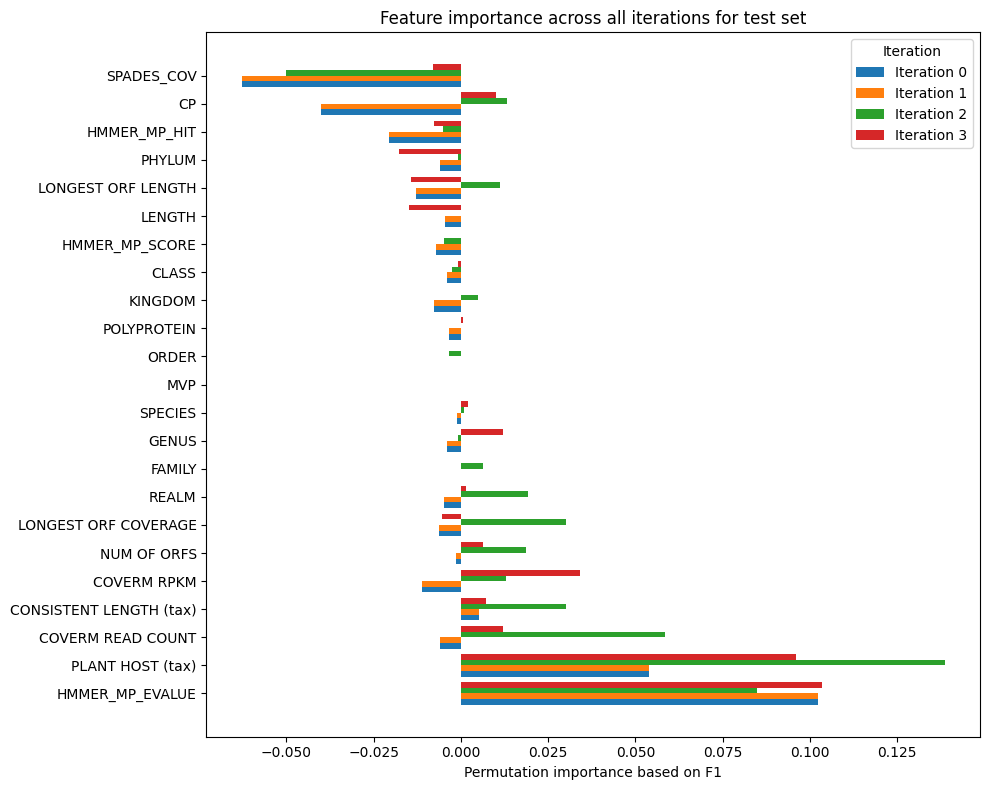

In [3]:
feature_importance_all(num_iterations=4, name="test")

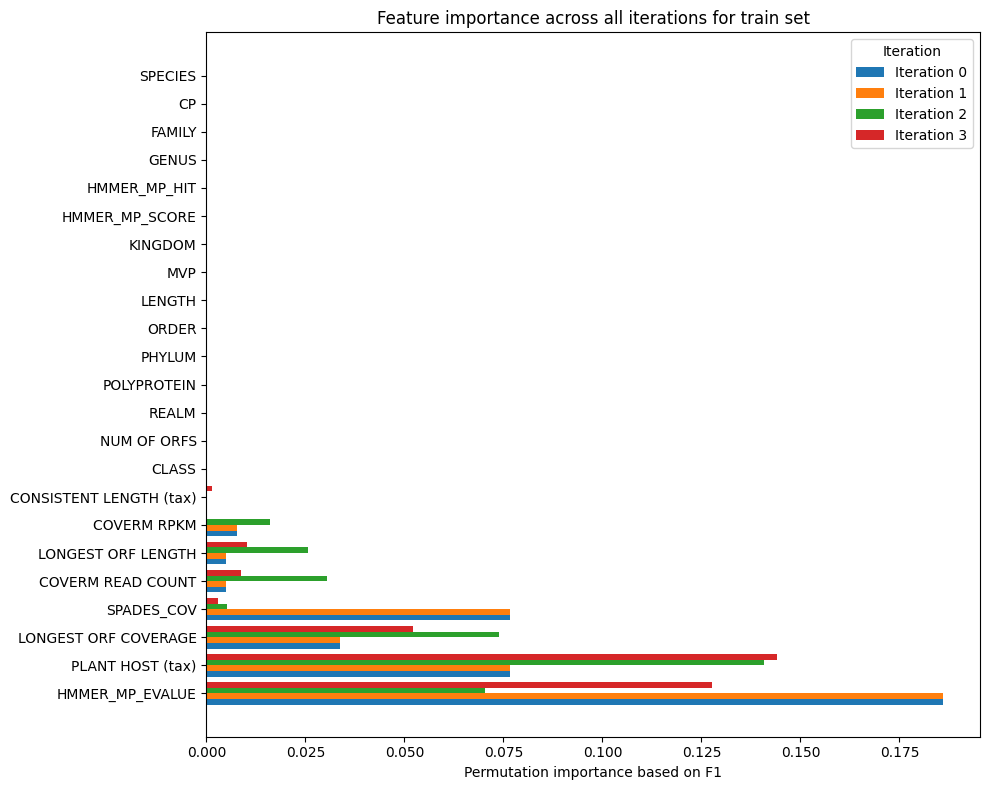

In [4]:
feature_importance_all(num_iterations=4, name="train")

In [5]:
import pandas as pd
import matplotlib.pyplot as plt
import os

def probability_distribution_all(num_iterations,
                                 dataset="test",
                                 input_dir="predictions"):

    plt.figure(figsize=(8,6))

    for iteration in range(num_iterations):

        df = pd.read_csv(
            os.path.join(
                input_dir,
                f"{dataset}_predictions_iter_{iteration}.csv"
            )
        )

        plt.hist(
            df["prob_Yes"],
            bins=20,
            range=(0,1),
            alpha=0.4,
            label=f"Iteration {iteration}"
        )

    plt.xlabel("Probability of Yes")
    plt.ylabel("Number of viruses/contigs")
    plt.title(f"{dataset.capitalize()} probability distribution")
    plt.xlim(0,1)
    plt.legend()
    plt.tight_layout()
    plt.show()

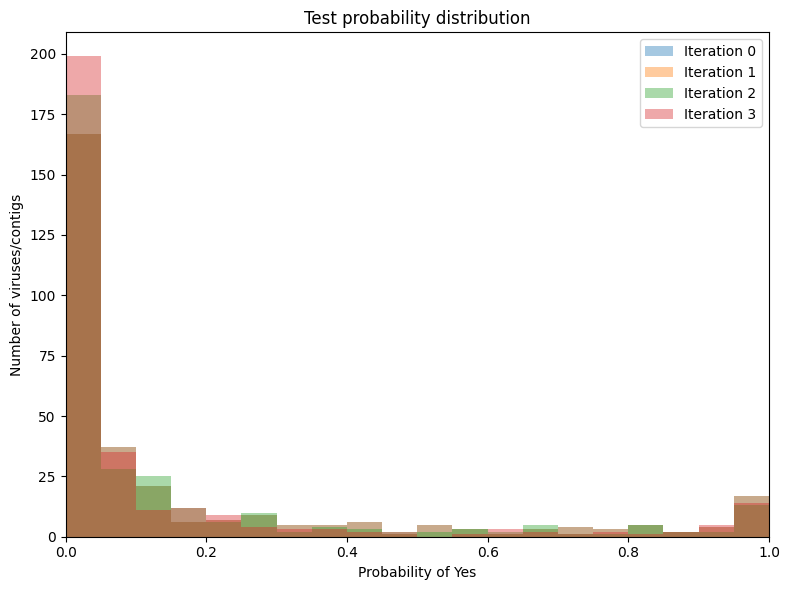

In [6]:
probability_distribution_all(num_iterations=4, dataset="test")

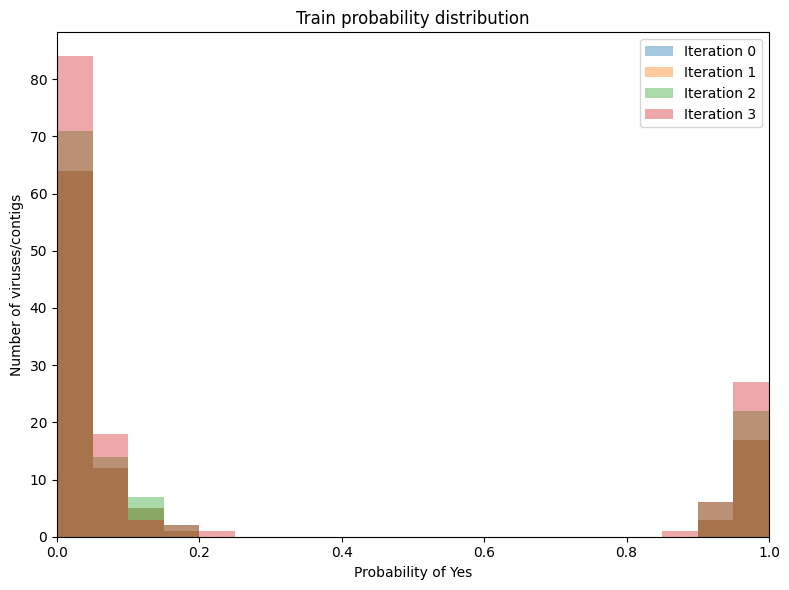

In [7]:
probability_distribution_all(num_iterations=4, dataset="train")

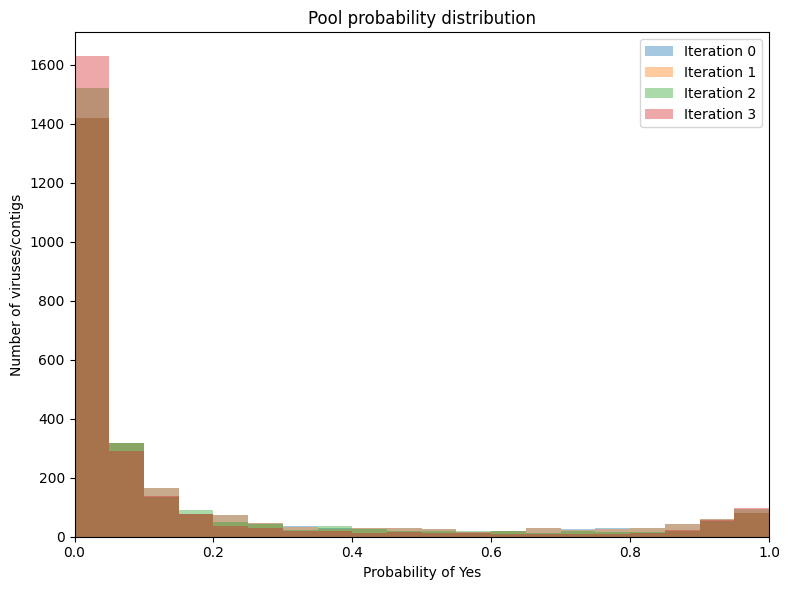

In [8]:
probability_distribution_all(num_iterations=4, dataset="pool")